<a href="https://colab.research.google.com/github/BalaMuppidathyK/AI-ML-Concepts/blob/Projects/Predictive_Maintainence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IMPORTING OF LIBRARIES AND DATASET**

In [ ]:
# --- STEP 1: LIBRARIES IMPORT & DATA LOADING ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loading
df = pd.read_csv('predictive_maintenance.csv')

# Displaying First 10 rows
print("Data successfully loaded! Here are the first 5 rows:")
display(df.head(10))

# Basic Information of Dataset (rows, columns, data types)
print("\nDataset Info:")
print(df.info())

Data successfully loaded! Here are the first 5 rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,No Failure
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,No Failure
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,No Failure
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,No Failure
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,No Failure



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
None


**DATASET PROCESSING AND DATA CLEANING**

In [ ]:
# --- STEP 2: DATA PROCESSING & CLEANING ---

# 1. Dropping Of Unnecessary columns
X_raw = df.drop(columns=['UDI', 'Product ID', 'Target', 'Failure Type'])
y = df['Target']g5

# 2. Categorical Column ('Type') into numbers (One-Hot Encoding)
X = pd.get_dummies(X_raw, columns=['Type'], drop_first=True)

# Displaying First 5 processed Rows
print("Processed Features (X) head:")
display(X.head())

Processed Features (X) head:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,True
1,298.2,308.7,1408,46.3,3,True,False
2,298.1,308.5,1498,49.4,5,True,False
3,298.2,308.6,1433,39.5,7,True,False
4,298.2,308.7,1408,40.0,9,True,False


**TRAINING AND TESTING DATA**

In [ ]:
# 3. Train-Test Split (80% training, 20% testing)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

# 4. Feature Scaling (Scaling values to same range)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nData Processing successfully completed and scaled!")
display(X.head())


Training data shape: (8000, 7)
Testing data shape: (2000, 7)

Data Processing successfully completed and scaled!


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,True
1,298.2,308.7,1408,46.3,3,True,False
2,298.1,308.5,1498,49.4,5,True,False
3,298.2,308.6,1433,39.5,7,True,False
4,298.2,308.7,1408,40.0,9,True,False


**MODEL TRAINING**

In [ ]:
# --- STEP 3: MODEL BUILDING & TRAINING ---
from sklearn.ensemble import RandomForestClassifier

# Creating Random Forest model
model = RandomForestClassifier(random_state=42)

# Training data (Scaled features and y_train) using this we are training the model(model fit)
model.fit(X_train_scaled, y_train)

print("Random Forest Model successfully trained!")

Random Forest Model successfully trained!


**MODEL TESTING**

Model Overall Accuracy: 98.50%

Confusion Matrix:
[[1935    4]
 [  26   35]]


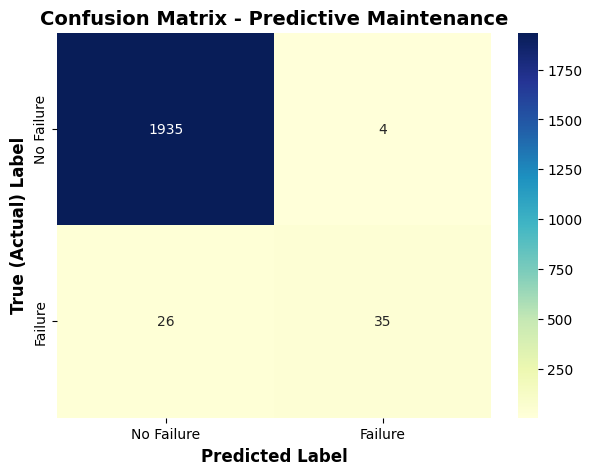


Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1939
           1       0.90      0.57      0.70        61

    accuracy                           0.98      2000
   macro avg       0.94      0.79      0.85      2000
weighted avg       0.98      0.98      0.98      2000



In [ ]:
# --- STEP 4: EVALUATION, ACCURACY METRICS & CONFUSION MATRIX ---
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Using Test data testing the model we have trained
y_pred = model.predict(X_test_scaled)

# 1. Accuracy Score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Overall Accuracy: {accuracy * 100:.2f}%\n")

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

class_labels = ['No Failure', 'Failure']

# Graph size & design
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', cbar=True,
            xticklabels=class_labels, yticklabels=class_labels)

plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True (Actual) Label', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix - Predictive Maintenance', fontsize=14, fontweight='bold')
plt.show()

# 3. Detailed Classification Report (Precision, Recall, F1-Score)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))